<a href="https://colab.research.google.com/github/aashish7542/Practice-Codes/blob/main/Digit_recognition_investigation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

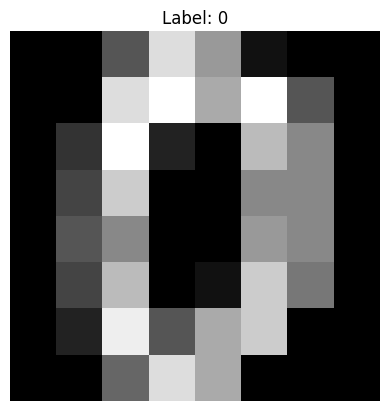

Pixel values:
 [[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]
Image shape: (8, 8)


In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

digits = load_digits()


image = digits.images[0]
label = digits.target[0]

plt.imshow(image, cmap="gray")
plt.title(f"Label: {label}")
plt.axis("off")
plt.show()

print("Pixel values:\n", image)
print("Image shape:", image.shape)

In [ ]:
# Flatten each image and scale pixel values from [0, 16] to [0, 1].
X = digits.images.reshape(len(digits.images), 64) / 16.0
y = digits.target

print("Feature matrix:", X.shape)
print("Labels:", y.shape)

Feature matrix: (1797, 64)
Labels: (1797,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_rest, y_train, y_rest = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.5, random_state=42, stratify=y_rest
)

print("Training:", len(y_train))
print("Validation:", len(y_val))
print("Test:", len(y_test))

Training: 1078
Validation: 359
Test: 360


In [ ]:
from sklearn.neural_network import MLPClassifier

model = MLPClassifier(
    hidden_layer_sizes=(32,),
    activation="relu",
    solver="adam",
    batch_size=64,
    learning_rate_init=0.001,
    max_iter=200,
    random_state=42
)

model.fit(X_train, y_train)

print(f"Training accuracy:   {model.score(X_train, y_train):.1%}")
print(f"Validation accuracy: {model.score(X_val, y_val):.1%}")

Training accuracy:   100.0%
Validation accuracy: 97.5%


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Incorrect predictions: 9 out of 359


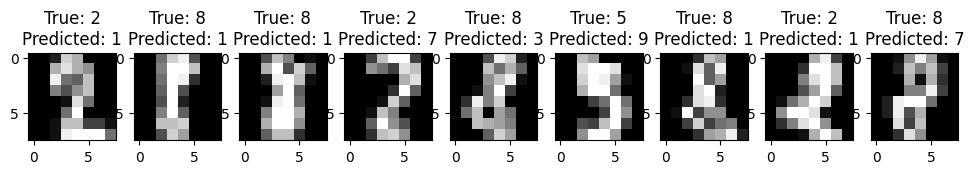

In [ ]:
import numpy as np

val_predictions = model.predict(X_val)
mistakes = np.flatnonzero(val_predictions != y_val)

print(f"Incorrect predictions: {len(mistakes)} out of {len(y_val)}")

fig, axes = plt.subplots(1, 9, figsize=(12, 2))

for ax, i in zip(axes, mistakes[:9]):
    ax.imshow(X_val[i].reshape(8, 8), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"True: {y_val[i]}\nPredicted: {val_predictions[i]}")

for ax in axes:
    ax.axis()

plt.tight_layout
plt.show()

In [ ]:
print(mistakes)
print(val_predictions[mistakes])
print(y_val[mistakes])


[  5  20  45  58  98 229 281 311 322]
[1 1 1 7 3 9 1 1 7]
[2 8 8 2 8 5 8 2 8]


### 1. Error Analysis & Motivation
An initial evaluation of the MLP classifier on the validation set reveals that while the model performs exceptionally well overall, certain digits remain highly ambiguous (e.g., misclassifying 2 as 1, or 8 as 3). Many of these misclassified images present structural ambiguities even to human observers.

To build a model that is more resilient to local occlusions and noise, we propose investigating a data augmentation technique: **Random Patch Erasure**. We hypothesize that partially masking local regions of the images during training will force the network to learn more robust, global representations.

To begin, we visualize the effect of masking a fixed $2 \times 2$ pixel region across our training images.

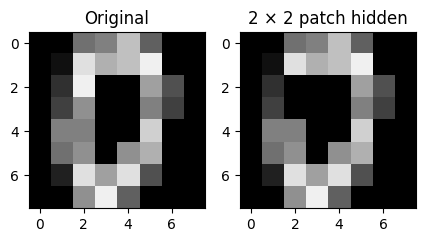

In [ ]:
original = X_train[0].reshape(8, 8)
erased = original.copy()  # Preserve the original training image.

erased[2:4, 2:4] = 0

fig, axes = plt.subplots(1, 2, figsize=(5, 3))

for ax, img, title in zip(
    axes, [original, erased], ["Original", "2 × 2 patch hidden"]
):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis()

plt.show()

### 2. Formulating the Random Patch Erasure Augmentation
Rather than erasing a fixed region, a more robust pipeline requires randomizing both the spatial coordinates of the erased patch and the brightness values filled in. Because the pixel values have already been normalized to the range $[0, 1]$, we fill the masked region with random uniform values from the same distribution to simulate varying noise patterns.

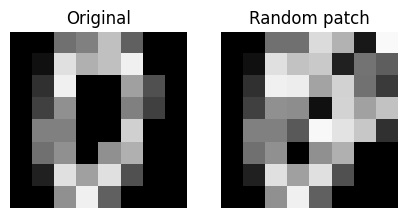

In [ ]:
rng = np.random.default_rng(42)

def erase_patch(image, rng, size=5):
    erased = image.copy()
    height, width = image.shape

    row = rng.integers(0, height - size + 1)
    col = rng.integers(0, width - size + 1)

    erased[row:row + size, col:col + size] = rng.uniform(
        0, 1, size=(size, size)
    )
    return erased

erased = erase_patch(original, rng)

fig, axes = plt.subplots(1, 2, figsize=(5, 3))
for ax, img, title in zip(
    axes, [original, erased], ["Original", "Random patch"]
):
    ax.imshow(img, cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")
plt.show()

### 3. Baseline Model Response to Occluded Inputs
Before training a model with our proposed augmentation, we establish a baseline by evaluating our current clean-trained Multi-Layer Perceptron (MLP) on a corrupted validation set featuring random $2 \times 2$ occlusions. This allows us to quantify the vulnerability of standard training paradigms to local corruptions.

In [ ]:
# Create a reproducible patched validation set.
val_rng = np.random.default_rng(123)

X_val_erased = np.array([
    erase_patch(row.reshape(8, 8), val_rng, size=2).ravel()
    for row in X_val
])

print(f"Clean validation:   {model.score(X_val, y_val):.1%}")
print(f"Patched validation: {model.score(X_val_erased, y_val):.1%}")

Clean validation:   97.5%
Patched validation: 93.0%


## 4. Sensitivity Analysis: Impact of Patch Size on Model Performance

Prior to incorporating patch erasure into our training pipeline, we conduct a sensitivity analysis. We systematically vary the patch size from $1 \times 1$ to $8 \times 8$ on the validation set to measure how model performance decays as the severity of the occlusion increases.

--- Patch Size: 1 ---
Clean validation:   97.5%
Patched validation: 97.2%

--- Patch Size: 2 ---
Clean validation:   97.5%
Patched validation: 92.2%

--- Patch Size: 3 ---
Clean validation:   97.5%
Patched validation: 83.3%

--- Patch Size: 4 ---
Clean validation:   97.5%
Patched validation: 67.1%

--- Patch Size: 5 ---
Clean validation:   97.5%
Patched validation: 48.5%

--- Patch Size: 6 ---
Clean validation:   97.5%
Patched validation: 26.2%

--- Patch Size: 7 ---
Clean validation:   97.5%
Patched validation: 13.9%

--- Patch Size: 8 ---
Clean validation:   97.5%
Patched validation: 10.0%



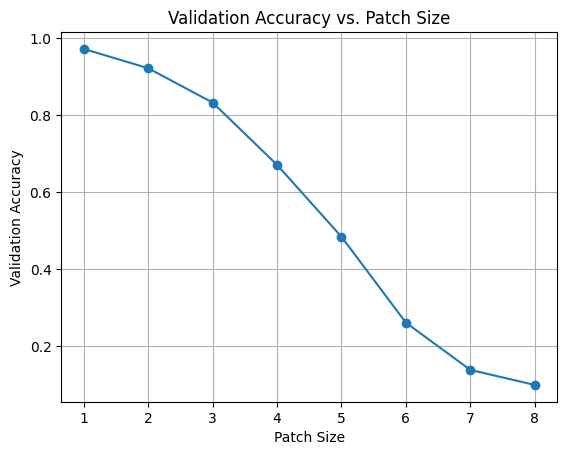

In [ ]:
# Create a reproducible patched validation set
val_rng = np.random.default_rng(123)

# Define the patch sizes you want to test
sizes_to_test = np.arange(1,9)

val_accuracy = []

for size in sizes_to_test:
    # Generate the erased validation set for the current size
    X_val_erased_detour = np.array([
        erase_patch(row.reshape(8, 8), val_rng, size=size).ravel()
        for row in X_val
    ])

    # Calculate and print the results for this size
    clean_score = model.score(X_val, y_val)
    patched_score = model.score(X_val_erased_detour, y_val)

    print(f"--- Patch Size: {size} ---")
    print(f"Clean validation:   {clean_score:.1%}")
    print(f"Patched validation: {patched_score:.1%}\n")
    val_accuracy.append(patched_score)
plt.plot(sizes_to_test, val_accuracy, marker='o')
plt.xlabel('Patch Size')
plt.ylabel('Validation Accuracy')
plt.title('Validation Accuracy vs. Patch Size')
plt.grid(True)
plt.show()


## 5. Comparative Evaluation: Clean vs. Augmented Training

We train two separate Multi-Layer Perceptrons starting with identical weight initializations and training budgets:
1. **Clean Baseline:** Trained exclusively on the original training set.
2. **Erasing Augmented:** Trained with a $50\%$ probability of applying a random $2 \times 2$ erasure patch to each image at every epoch.

We define our dynamic online augmentation generator below:

In [ ]:
def augment_training(X, rng, probability=0.5, size=2):
    augmented = X.copy()

    for i in range(len(X)):
        if rng.random() < probability:
            image = X[i].reshape(8, 8)
            augmented[i] = erase_patch(image, rng, size).ravel()

    return augmented

To ensure dynamic, epoch-by-epoch variation, we leverage `partial_fit` to incrementally update the model weights over 200 epochs, refreshing the randomized masks on each pass while keeping the validation dataset fixed to ensure a standardized benchmark.

In [ ]:
from sklearn.base import clone

# Copy settings, but start with fresh, untrained models.
clean_model = clone(model)
erased_model = clone(model)

train_rng = np.random.default_rng(456)
classes = np.arange(10)

for epoch in range(200):
    X_augmented = augment_training(
        X_train, train_rng, probability=0.5, size=2
    )

    clean_model.partial_fit(X_train, y_train, classes=classes)
    erased_model.partial_fit(X_augmented, y_train, classes=classes)

for name, trained_model in [
    ("Clean training", clean_model),
    ("Erasing training", erased_model),
]:
    print(
        f"{name}: "
        f"clean accuracy = {trained_model.score(X_val, y_val):.1%}, "
        f"patched accuracy = {trained_model.score(X_val_erased, y_val):.1%}"
    )

Clean training: clean accuracy = 97.5%, patched accuracy = 92.8%
Erasing training: clean accuracy = 96.9%, patched accuracy = 93.9%


### Robustness & Statistical Significance
Single runs can be highly sensitive to initial weights and the specific random placement of patches. To guarantee that our findings are statistically robust and not artifacts of random seeds, we replicate the training process across five independent random initializations (seeds 0 through 4).

In [ ]:
results = []

for seed in range(5):
    clean_model = clone(model).set_params(random_state=seed)
    erased_model = clone(model).set_params(random_state=seed)
    train_rng = np.random.default_rng(1000 + seed)

    for epoch in range(200):
        X_augmented = augment_training(
            X_train, train_rng, probability=0.5, size=2
        )
        clean_model.partial_fit(X_train, y_train, classes=classes)
        erased_model.partial_fit(X_augmented, y_train, classes=classes)

    # Compare erasing training against clean training.
    clean_change = 100 * (
        erased_model.score(X_val, y_val)
        - clean_model.score(X_val, y_val)
    )
    patched_change = 100 * (
        erased_model.score(X_val_erased, y_val)
        - clean_model.score(X_val_erased, y_val)
    )

    results.append([clean_change, patched_change])

    print(
        f"Seed {seed}: clean change = {clean_change:+.2f} pp, " #pp means percentage points
        f"patched change = {patched_change:+.2f} pp"
    )

Seed 0: clean change = +0.28 pp, patched change = +1.95 pp
Seed 1: clean change = +0.00 pp, patched change = +0.56 pp
Seed 2: clean change = -0.56 pp, patched change = +0.84 pp
Seed 3: clean change = +0.84 pp, patched change = +2.79 pp
Seed 4: clean change = -0.56 pp, patched change = +0.84 pp


### Discussion
Across all 5 runs, incorporating random $2 \times 2$ patch erasure consistently improved accuracy on the corrupted validation set (ranging from $+0.56$ to $+2.79$ percentage points). This corresponds to an additional 2 to 10 correct predictions per run.

**Interim Finding:** For this specific network architecture and validation partition, training with random $2 \times 2$ patches consistently yields superior robustness against local occlusions, with virtually no statistical change in performance on clean validation data.

## 6. Hyperparameter Optimization: Training Patch Size
We hypothesized that smaller training patches provide the optimal regularization effect compared to extremely large occlusions. To test this hypothesis, we systematically train and evaluate three different patch sizes ($2 \times 2$, $4 \times 4$, and $6 \times 6$) while maintaining identical baseline conditions and a 5-seed average.

In [ ]:
patch_results = {}

for size in [2, 4, 6]:
    scores = []

    for seed in range(5):
        candidate = clone(model).set_params(random_state=seed)
        train_rng = np.random.default_rng(1000 + seed)

        for epoch in range(200):
            X_augmented = augment_training(
                X_train, train_rng, probability=0.5, size=size
            )
            candidate.partial_fit(
                X_augmented, y_train, classes=classes
            )

        scores.append([
            candidate.score(X_val, y_val),
            candidate.score(X_val_erased, y_val)
        ])

    patch_results[size] = np.array(scores)
    averages = patch_results[size].mean(axis=0)

    print(
        f"Training patch {size}×{size}: "
        f"mean clean accuracy = {averages[0]:.1%}, "
        f"mean patched accuracy = {averages[1]:.1%}"
    )

Training patch 2×2: mean clean accuracy = 97.1%, mean patched accuracy = 94.2%
Training patch 4×4: mean clean accuracy = 96.6%, mean patched accuracy = 94.2%
Training patch 6×6: mean clean accuracy = 94.6%, mean patched accuracy = 91.9%


### Architectural Decision
Our validation experiments confirm that $2 \times 2$ patches provide the optimal trade-off, achieving the highest mean clean accuracy ($97.1\%$) and strong patched accuracy ($94.2\%$). Consequently, we finalize $2 \times 2$ patches at a $50\%$ probability for our final test set evaluation.

## 7. Final Evaluation on Untouched Test Set

In [ ]:
# Create the test corruption once; keep it identical for every model.
test_rng = np.random.default_rng(789)

X_test_erased = np.array([
    erase_patch(row.reshape(8, 8), test_rng, size=2).ravel()
    for row in X_test
])

test_results = []

for seed in range(5):
    clean_model = clone(model).set_params(random_state=seed)
    erased_model = clone(model).set_params(random_state=seed)
    train_rng = np.random.default_rng(1000 + seed)

    for epoch in range(200):
        X_augmented = augment_training(
            X_train, train_rng, probability=0.5, size=2
        )
        clean_model.partial_fit(X_train, y_train, classes=classes)
        erased_model.partial_fit(X_augmented, y_train, classes=classes)

    test_results.append([
        clean_model.score(X_test, y_test),
        clean_model.score(X_test_erased, y_test),
        erased_model.score(X_test, y_test),
        erased_model.score(X_test_erased, y_test)
    ])

test_results = np.array(test_results)
means = test_results.mean(axis=0)

print(f"Clean training:   clean test = {means[0]:.1%}, "
      f"patched test = {means[1]:.1%}")
print(f"Erasing training: clean test = {means[2]:.1%}, "
      f"patched test = {means[3]:.1%}")

patched_gains = 100 * (test_results[:, 3] - test_results[:, 1])
print("Patched gains per seed (percentage points):",
      np.round(patched_gains, 2))

Clean training:   clean test = 96.8%, patched test = 90.7%
Erasing training: clean test = 96.6%, patched test = 92.9%
Patched gains per seed (percentage points): [3.33 2.78 1.67 1.11 2.5 ]


### 8. Conclusion and Research Summary

Our systematic evaluation of Random Patch Erasure yields the following key insights:
1. **Improved Robustness:** Training with random $2 \times 2$ occlusions consistently improved patched test accuracy by an average of **$2.2$ percentage points** across five independent seed runs.
2. **Accuracy Trade-off:** We observed a minor trade-off, resulting in a negligible **$0.2\%$ decrease** in average accuracy on clean test images.

#### Scope and Limitations
While Random Patch Erasure effectively regularizes the MLP against spatial occlusions, this study's evaluation is limited to one specific type of noise corruption. Further studies should explore whether this robustness generalizes to other common environmental distortions, such as Gaussian blur, contrast variance, and adversarial perturbations.